# Generate Model Climatology

---

This notebook takes in the `.zarr` raw S2S array we made in `1_concatenate_S2S.ipynb` and generates a daily climatology (with band pass filtering) to remove from the raw S2S output to create anomalies.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import xarray as xr
xr.set_options(keep_attrs=True)
import dask.array as da

In [2]:
from dask_cluster import get_client
client = get_client()

Choose which model and variables you are wanting in your climatology `zarr` file.

In [3]:
model = "MPAS_60km"
var = ["t2m","tp","psl","gh_500"]
zarr_dir = "output/"

First, we need to calculate the daily climatology following the SubX protocol. We'll load in our big `zarr`, take the ensemble mean, and then generate the climatology.

In [4]:
ds = xr.open_zarr(f"{zarr_dir}{model}.raw.daily.geospatial.zarr/",consolidated=True)
display(ds)

<xarray.Dataset> Size: 660GB
Dimensions:  (init: 1252, member: 11, lead: 46, lat: 181, lon: 360)
Coordinates:
  * init     (init) datetime64[ns] 10kB 1999-01-04 1999-01-11 ... 2022-12-26
  * lat      (lat) float32 724B -90.0 -89.0 -88.0 -87.0 ... 87.0 88.0 89.0 90.0
  * lead     (lead) int64 368B 0 1 2 3 4 5 6 7 8 ... 37 38 39 40 41 42 43 44 45
  * lon      (lon) float32 1kB 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
  * member   (member) int64 88B 1 2 3 4 5 6 7 8 9 10 11
Data variables:
    gh_500   (init, member, lead, lat, lon) float32 165GB dask.array<chunksize=(1, 11, 46, 181, 360), meta=np.ndarray>
    psl      (init, member, lead, lat, lon) float32 165GB dask.array<chunksize=(1, 11, 46, 181, 360), meta=np.ndarray>
    t2m      (init, member, lead, lat, lon) float32 165GB dask.array<chunksize=(1, 11, 46, 181, 360), meta=np.ndarray>
    tp       (init, member, lead, lat, lon) float32 165GB dask.array<chunksize=(1, 11, 46, 181, 360), meta=np.ndarray>

Here I "persist" the ensemble mean. This essentially runs the calculation in the background, but maintains the result as dask arrays distributed across the cluster, rather than loading it into RAM memory on the main node.

In [5]:
ds = ds.mean("member").persist()

## Generate Climatology

We'll be taking an average over the `dayofyear` of the `init` dimension, so it's best to rechunk so that `init` is a single chunk. That will speed things up. I'll make `lead` chunks of 1 since we are doing a lead-dependent climatology.

I usually run `.persist()` after re-chunking so that it can re-load it's chunks properly.

In [6]:
ds = ds.chunk({"init": -1, "lead": 1, "lat": "auto", "lon": "auto"}).persist()

All of the following is from Ray Bell's climatology script for SubX that Kathy uses. Direct questions to them about the methodology! This uses a smoothed window approach to smooth out the daily climatology for initializations.

In [7]:
days = ds.groupby("init.dayofyear").mean("init").sizes["dayofyear"]

## Loop through all vars to make climatology

In [8]:
da_day_clim_smooth_vars = []
for i in var:
    print(i)
    da_day_clim = ds[i].groupby("init.dayofyear").mean("init")
    # Rechunk to make dayofyear climatology one chunk.
    da_day_clim = da_day_clim.chunk({"dayofyear": days}).persist()
    # Just mimicking the chunk sizes from our climatology.
    x = da.full((days, da_day_clim.lead.size, da_day_clim.lat.size, da_day_clim.lon.size),
        np.nan,dtype="float32",chunks=(days, 1, 181, 360),)
    # Pad the daily climatolgy with nans
    _da = xr.DataArray(x,dims=["dayofyear", "lead", "lat", "lon"],
        coords=[da_day_clim.dayofyear, da_day_clim.lead, da_day_clim.lat, da_day_clim.lon],name=i,)
    da_day_clim_wnan = da_day_clim.combine_first(_da)
    
    # Smooth it out if we don't have inits for each 'dayofyear'
    if days<366:
        full_year = np.arange(1, 367)
        da_day_clim = da_day_clim.reindex(dayofyear=full_year)
        da_day_clim_smooth = da_day_clim.copy()
    else:
        da_day_clim_smooth = da_day_clim_wnan.copy()

    # Period rolling twice to make it triangular smoothing
    for j in range(2):
        # Extand the DataArray to allow rolling to do periodic
        da_day_clim_smooth = xr.concat([da_day_clim_smooth[-15:], da_day_clim_smooth, da_day_clim_smooth[:15]],"dayofyear",)
        # Rolling mean
        da_day_clim_smooth = da_day_clim_smooth.rolling(dayofyear=31, center=True, min_periods=1).mean()
        # Drop the periodic boundaries
        da_day_clim_smooth = da_day_clim_smooth.isel(dayofyear=slice(15, -15))
        
    # Extract the original days
    da_day_clim_smooth = da_day_clim_smooth.sel(dayofyear=da_day_clim.dayofyear)
    da_day_clim_smooth.name = i
    
    da_day_clim_smooth_vars.append(da_day_clim_smooth)

t2m
tp
psl
gh_500


- Next we need to merge the variables together into one xarray dataset.

In [9]:
ds_day_clim_smooth_vars = xr.merge(da_day_clim_smooth_vars)

In [10]:
ds_day_clim_smooth_vars = ds_day_clim_smooth_vars.chunk({"dayofyear": -1, "lead": 1, "lat": 181, "lon": 360}).persist()

In [11]:
ds_day_clim_smooth_vars

<xarray.Dataset> Size: 18GB
Dimensions:    (lat: 181, lead: 46, lon: 360, dayofyear: 366)
Coordinates:
  * lat        (lat) float32 724B -90.0 -89.0 -88.0 -87.0 ... 88.0 89.0 90.0
  * lead       (lead) int64 368B 0 1 2 3 4 5 6 7 8 ... 38 39 40 41 42 43 44 45
  * lon        (lon) float32 1kB 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
  * dayofyear  (dayofyear) int64 3kB 1 2 3 4 5 6 7 ... 361 362 363 364 365 366
Data variables:
    t2m        (dayofyear, lead, lat, lon) float32 4GB dask.array<chunksize=(366, 1, 181, 360), meta=np.ndarray>
    tp         (dayofyear, lead, lat, lon) float32 4GB dask.array<chunksize=(366, 1, 181, 360), meta=np.ndarray>
    psl        (dayofyear, lead, lat, lon) float32 4GB dask.array<chunksize=(366, 1, 181, 360), meta=np.ndarray>
    gh_500     (dayofyear, lead, lat, lon) float32 4GB dask.array<chunksize=(366, 1, 181, 360), meta=np.ndarray>
Attributes:
    cell_methods:  time: mean
    long_name:     Reference height temperature
    units:         K

In [49]:
%time ds_day_clim_smooth_vars.to_zarr(f"{zarr_dir}{model}.climatology.daily.geospatial.zarr", mode="w",consolidated=True)

CPU times: user 175 ms, sys: 12.5 ms, total: 187 ms
Wall time: 24.4 s


Just a quick check that things look right

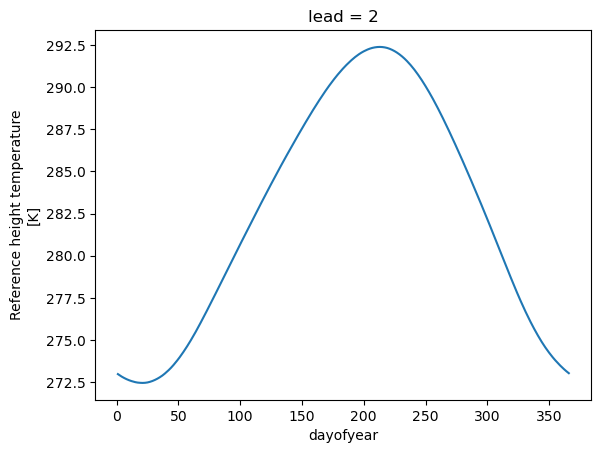

In [12]:
ds_day_clim_smooth_vars.t2m.sel(lead=2,lat=slice(31,60)).mean(("lat","lon")).plot()